# 05 · Model Training: financial metric prediction
Trains one model per financial metric at three levels, using **only `data/final/`**:

| Level | Question | Targets |
|---|---|---|
| **Monthly** | Next month's performance | units, demand (units, share %, MoM growth %), price, revenue, profit, margin %, unit ROI %, cumulative ROI % |
| **Yearly** | This year's performance | units, demand (units, share %, YoY growth %), price, revenue, profit, margin %, ROI % (year and cumulative) |
| **Product (launch)** | Investing in or launching a product | first 12/24-month units, demand, price, revenue, profit, margin, ROI, **break-even months**, **never breaks even** (classifier) |

**Model:** scikit-learn `HistGradientBoosting` (same algorithm family as LightGBM: histogram-based gradient-boosted trees, native NaN handling).

**How training stops (early stopping):** trees are added in batches of 25 and the error is checked on a **time-ordered validation set** after every batch.
When validation error hasn't improved for 6 batches (150 trees), training stops and the best iteration count is kept. The model is then
**refitted on train + validation** with that many trees and scored **once** on the untouched test set.

**Target transforms:** skewed non-negative targets (units, revenue, demand) are trained on `log1p`. Profit, which can be negative, uses a
signed log `sign(y)·log1p(|y|)`. Predictions are transformed back before scoring, so all metrics are in real units ($, units, %).

**Baselines:** every model is compared with a naive forecast: *last month's value* (monthly), *last year's value* (yearly), or the
*category median from train* (product). A model is only useful if it beats its baseline.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# One consistent, colour-blind-checked palette for every chart (fixed order: colour follows the entity)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ = sns.blend_palette(["#cde2fb", "#2a78d6", "#0d366b"], as_cmap=True)
DIV = sns.blend_palette(["#2a78d6", "#f0efec", "#e34948"], as_cmap=True)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=SERIES),
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
})
usd = mtick.StrMethodFormatter("${x:,.0f}")
import matplotlib.dates as mdates
def fmt_dates(ax):
    loc = mdates.AutoDateLocator(minticks=3, maxticks=8); ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
def savefig(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
import json, time, warnings, joblib
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, f1_score, accuracy_score, log_loss
warnings.filterwarnings("ignore", category=UserWarning)

FINAL = ROOT / "data/final"
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
METRICS = ROOT / "reports/metrics"; METRICS.mkdir(parents=True, exist_ok=True)
spec = json.loads((FINAL / "feature_spec.json").read_text())
SEED = 42

## 1. Training utilities

In [2]:
# Target transforms: train in a well-behaved space, score in real units
TRANSFORMS = {
    "log1p":  (np.log1p, lambda z: np.expm1(z).clip(min=0)),
    "slog":   (lambda y: np.sign(y) * np.log1p(np.abs(y)), lambda z: np.sign(z) * np.expm1(np.abs(z))),
    "none":   (lambda y: y, lambda z: z),
}

def make_model(**kw):
    return HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1.0,
                                         max_features=0.8, early_stopping=False, random_state=SEED, warm_start=True, max_iter=1, **kw)

def fit_early_stopping(X_tr, y_tr, X_va, y_va, inv, step=25, max_iter=2000, patience=6, classifier=False):
    """Grow trees in batches, track validation error, stop after `patience` batches without improvement."""
    if classifier:
        m = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0,
                                           early_stopping=False, random_state=SEED, warm_start=True, max_iter=1, class_weight="balanced")
    else:
        m = make_model()
    curve, best, best_it, wait, it = [], np.inf, 0, 0, 0
    while it < max_iter:
        it += step
        m.set_params(max_iter=it)
        m.fit(X_tr, y_tr)
        if classifier:
            tr_loss = log_loss(y_tr, m.predict_proba(X_tr)[:, 1]); va_loss = log_loss(y_va, m.predict_proba(X_va)[:, 1])
        else:
            tr_loss = mean_absolute_error(inv(y_tr), inv(m.predict(X_tr)))
            va_loss = mean_absolute_error(inv(y_va), inv(m.predict(X_va)))
        curve.append((it, tr_loss, va_loss))
        if not np.isfinite(best) or va_loss < best * (1 - 1e-4):   # needs a >0.01% improvement to count
            best, best_it, wait = va_loss, it, 0
        else:
            wait += 1
            if wait >= patience:
                break
    stop_reason = "early-stopped (no val improvement)" if wait >= patience else "reached max_iter"
    return best_it, pd.DataFrame(curve, columns=["iteration", "train_mae", "val_mae"]), stop_reason

def regression_metrics(y, p, prefix=""):
    y, p = np.asarray(y, float), np.asarray(p, float)
    out = {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** .5, "R2": r2_score(y, p)}
    if (y >= 0).all() and y.sum() > 0:
        out["WAPE_%"] = np.abs(y - p).sum() / np.abs(y).sum() * 100   # weighted abs % error: robust MAPE for sales data
    return {prefix + k: v for k, v in out.items()}

def train_target(level, target, train, test, features, tf, val_mask, baseline_test=None, classifier=False):
    t0 = time.time()
    d_tr = train[train[target].notna()]; d_te = test[test[target].notna()]
    vm = val_mask.loc[d_tr.index]
    fwd, inv = TRANSFORMS[tf]
    y_tr_all = d_tr[target].values if classifier else fwd(d_tr[target].values)
    X_all = d_tr[features]
    best_it, curve, reason = fit_early_stopping(X_all[~vm.values], y_tr_all[~vm.values], X_all[vm.values], y_tr_all[vm.values], inv,
                                                classifier=classifier)
    # Refit on train + validation with the chosen number of trees
    final = (HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0,
                                            max_iter=best_it, random_state=SEED, class_weight="balanced")
             if classifier else make_model().set_params(warm_start=False, max_iter=best_it))
    final.fit(X_all, y_tr_all)
    row = {"level": level, "target": target, "transform": tf, "n_train": len(d_tr), "n_test": len(d_te), "n_features": len(features),
           "best_iteration": best_it, "stop_reason": reason, "train_seconds": round(time.time() - t0, 1)}
    if classifier:
        proba = final.predict_proba(d_te[features])[:, 1]; pred = (proba >= .5).astype(int)
        row.update({"test_AUC": roc_auc_score(d_te[target], proba), "test_F1": f1_score(d_te[target], pred),
                    "test_accuracy": accuracy_score(d_te[target], pred),
                    "baseline_accuracy": max(d_te[target].mean(), 1 - d_te[target].mean())})
        preds = proba
    else:
        preds = inv(final.predict(d_te[features]))
        row.update(regression_metrics(d_te[target], preds, "test_"))
        b = baseline_test.loc[d_te.index] if baseline_test is not None else None
        if b is not None and b.notna().any():
            ok = b.notna()
            row.update(regression_metrics(d_te[target][ok], b[ok], "baseline_"))
            row["model_MAE_on_baseline_rows"] = mean_absolute_error(d_te[target][ok], preds[ok.values])
    (MODELS / level).mkdir(exist_ok=True)
    joblib.dump({"model": final, "features": features, "transform": tf, "target": target, "level": level,
                 "best_iteration": best_it, "trained_on": f"{len(d_tr)} rows"}, MODELS / level / f"{target}.joblib")
    return row, curve, pd.Series(preds, index=d_te.index)

## 2. Monthly models (next-month forecasts)
- **Train / validation:** train ≤ Mar 2025, validation Apr–Sep 2025 (early stopping), then refit on everything ≤ Sep 2025.
- **Test:** Oct 2025 → Sep 2026 (never seen during training or early stopping).
- **Baseline:** last month's actual value (`*_lag1`). For the price model, all same-month price inputs are removed.

In [3]:
m_train = pd.read_csv(FINAL / "monthly_train.csv", parse_dates=["month"])
m_test  = pd.read_csv(FINAL / "monthly_test.csv", parse_dates=["month"])
MF = spec["monthly"]["features"]
m_val_mask = m_train.month >= "2025-04-01"
print(f"train {len(m_train):,} (of which validation {m_val_mask.sum():,}) | test {len(m_test):,} | features {len(MF)}")

def lag_baseline(df, target):
    # Naive forecast = last month's value. Derived targets are rebuilt from lag columns.
    direct = {"units_sold": "units_sold_lag1", "demand_units": "demand_units_lag1", "avg_price": "avg_price_lag1",
              "net_profit": "net_profit_lag1", "gross_revenue": "gross_revenue_lag1", "profit_margin_pct": "profit_margin_pct_lag1",
              "demand_share_pct": "demand_share_pct_lag1", "roi_cum_pct": "roi_cum_pct_lag1"}
    if target in direct: return df[direct[target]]
    if target == "demand_growth_mom_pct": return (df.demand_units_lag1 / df.demand_units_lag2 - 1).replace([np.inf, -np.inf], np.nan) * 100
    if target == "roi_unit_pct": return pd.Series(np.nan, index=df.index)
    return None

MONTHLY_PLAN = {"units_sold": "log1p", "demand_units": "log1p", "demand_share_pct": "log1p", "demand_growth_mom_pct": "none",
                "avg_price": "log1p", "gross_revenue": "log1p", "net_profit": "slog", "profit_margin_pct": "none",
                "roi_unit_pct": "none", "roi_cum_pct": "none"}
results, curves, monthly_preds = [], {}, {}
for tgt, tf in MONTHLY_PLAN.items():
    feats = [f for f in MF if f not in spec["monthly"]["drop_when_target_is_price"] + ["everyday_price"]] if tgt == "avg_price" else MF
    row, curve, pred = train_target("monthly", tgt, m_train, m_test, feats, tf, m_val_mask, lag_baseline(m_test, tgt))
    results.append(row); curves[("monthly", tgt)] = curve; monthly_preds[tgt] = pred
    print(f"{tgt:24s} best_iter={row['best_iteration']:>4}  {row['stop_reason']:34s} test R²={row['test_R2']:.3f}  ({row['train_seconds']}s)")

train 52,245 (of which validation 7,498) | test 16,054 | features 110


units_sold               best_iter=1075  early-stopped (no val improvement) test R²=0.902  (30.7s)


demand_units             best_iter=1200  early-stopped (no val improvement) test R²=0.921  (36.6s)


demand_share_pct         best_iter= 350  early-stopped (no val improvement) test R²=0.987  (10.7s)


demand_growth_mom_pct    best_iter= 700  early-stopped (no val improvement) test R²=0.727  (21.8s)


...

gross_revenue            best_iter= 850  early-stopped (no val improvement) test R²=0.895  (26.4s)


net_profit               best_iter= 250  early-stopped (no val improvement) test R²=0.652  (8.0s)


profit_margin_pct        best_iter=2000  reached max_iter                   test R²=0.991  (834.1s)


roi_unit_pct             best_iter=2000  reached max_iter                   test R²=0.989  (509.7s)


roi_cum_pct              best_iter=2000  reached max_iter                   test R²=0.999  (69.7s)


## 3. Yearly models
- **Train / validation:** fit on years ≤ 2023, validate on 2024 (early stopping), refit on ≤ 2024.
- **Test:** 2025 (full year). **Baseline:** last year's value (`*_prev_year`).

In [4]:
y_train = pd.read_csv(FINAL / "yearly_train.csv"); y_test = pd.read_csv(FINAL / "yearly_test.csv")
YF = spec["yearly"]["features"]
y_val_mask = y_train.year == 2024
y_train_fit = y_train  # validation rows are inside train and masked
def prev_year_baseline(df, target):
    col = f"{target}_prev_year"
    if col in df: return df[col].where(df.months_active_prev_year == 12)   # only compare against full previous years
    return None
YEARLY_PLAN = {"units_sold": "log1p", "demand_units": "log1p", "demand_share_pct": "log1p", "demand_growth_yoy_pct": "none",
               "avg_price": "log1p", "gross_revenue": "log1p", "net_profit": "slog", "profit_margin_pct": "none",
               "roi_year_pct": "none", "roi_cum_pct": "none"}
for tgt, tf in YEARLY_PLAN.items():
    row, curve, _ = train_target("yearly", tgt, y_train, y_test, YF, tf, y_val_mask, prev_year_baseline(y_test, tgt))
    results.append(row); curves[("yearly", tgt)] = curve
    print(f"{tgt:24s} best_iter={row['best_iteration']:>4}  {row['stop_reason']:34s} test R²={row['test_R2']:.3f}")

units_sold               best_iter= 375  early-stopped (no val improvement) test R²=0.908


demand_units             best_iter= 200  early-stopped (no val improvement) test R²=0.878


demand_share_pct         best_iter=2000  reached max_iter                   test R²=0.979


demand_growth_yoy_pct    best_iter=  50  early-stopped (no val improvement) test R²=0.248


avg_price                best_iter=2000  reached max_iter                   test R²=0.989


gross_revenue            best_iter= 750  early-stopped (no val improvement) test R²=0.763


net_profit               best_iter= 275  early-stopped (no val improvement) test R²=0.545


profit_margin_pct        best_iter= 675  early-stopped (no val improvement) test R²=0.982


roi_year_pct             best_iter=1150  early-stopped (no val improvement) test R²=0.906


roi_cum_pct              best_iter=2000  reached max_iter                   test R²=0.971


## 4. Product launch models (first 12 / 24 months, break-even)
Uses **`launch_features`** only: what an entrepreneur knows *before* launching (price, category, size, fees, costs, expected rating).
No review counts, so there's no leakage of realised sales.
- **Validation:** a stratified 20% slice of the product-train set for early stopping. **Test:** the 271 held-out products.
- **Baseline:** median of the target within the same category (computed on train).

This is the hardest task: predicting success *before* any sales exist. Expect lower R² than the monthly models, which can see recent sales.

In [5]:
p_train = pd.read_csv(FINAL / "product_train.csv"); p_test = pd.read_csv(FINAL / "product_test.csv")
LF = spec["product"]["launch_features"]
rng = np.random.default_rng(SEED)
p_val_mask = pd.Series(False, index=p_train.index)
for _, idx in p_train.groupby("category_group").groups.items():
    idx = np.array(idx); p_val_mask.loc[rng.choice(idx, size=max(1, int(round(len(idx) * .2))), replace=False)] = True

def category_median_baseline(target):
    med = p_train.groupby("category_group")[target].median()
    return p_test.category_group.map(med).fillna(p_train[target].median())

PRODUCT_PLAN = {"units_sold_12m": "log1p", "demand_units_12m": "log1p", "avg_monthly_demand_12m": "log1p", "demand_share_pct_12m": "log1p",
                "avg_price_12m": "log1p", "revenue_12m": "log1p", "profit_12m": "slog", "margin_pct_12m": "none", "roi_pct_12m": "none",
                "units_sold_24m": "log1p", "revenue_24m": "log1p", "profit_24m": "slog", "margin_pct_24m": "none", "roi_pct_24m": "none",
                "break_even_months": "log1p"}
product_preds = {}
for tgt, tf in PRODUCT_PLAN.items():
    row, curve, pred = train_target("product", tgt, p_train, p_test, LF, tf, p_val_mask, category_median_baseline(tgt))
    results.append(row); curves[("product", tgt)] = curve; product_preds[tgt] = pred
    print(f"{tgt:24s} best_iter={row['best_iteration']:>4}  {row['stop_reason']:34s} test R²={row['test_R2']:.3f}")

row, curve, pred = train_target("product", "never_breaks_even", p_train, p_test, LF, "none", p_val_mask, classifier=True)
results.append(row); curves[("product", "never_breaks_even")] = curve; product_preds["never_breaks_even"] = pred
print(f"never_breaks_even (classifier) best_iter={row['best_iteration']}  AUC={row['test_AUC']:.3f}  F1={row['test_F1']:.3f}  acc={row['test_accuracy']:.3f} vs baseline {row['baseline_accuracy']:.3f}")

units_sold_12m           best_iter= 150  early-stopped (no val improvement) test R²=0.207


demand_units_12m         best_iter= 375  early-stopped (no val improvement) test R²=0.284


avg_monthly_demand_12m   best_iter= 275  early-stopped (no val improvement) test R²=0.256


demand_share_pct_12m     best_iter= 100  early-stopped (no val improvement) test R²=0.083


avg_price_12m            best_iter= 550  early-stopped (no val improvement) test R²=0.962


...

profit_24m               best_iter= 125  early-stopped (no val improvement) test R²=0.337


margin_pct_24m           best_iter= 725  early-stopped (no val improvement) test R²=0.964


roi_pct_24m              best_iter=  75  early-stopped (no val improvement) test R²=0.802


break_even_months        best_iter= 175  early-stopped (no val improvement) test R²=0.336


never_breaks_even (classifier) best_iter=175  AUC=0.981  F1=0.870  acc=0.934 vs baseline 0.742


## 5. Results: did training work?

In [6]:
res = pd.DataFrame(results)
res.to_csv(METRICS / "model_metrics.csv", index=False)
show = res[["level", "target", "best_iteration", "stop_reason", "n_train", "n_test", "test_MAE", "test_R2", "test_WAPE_%",
            "baseline_MAE", "model_MAE_on_baseline_rows", "baseline_R2"]].copy()
show["beats_baseline"] = np.where(show.baseline_MAE.notna(), show.model_MAE_on_baseline_rows < show.baseline_MAE, np.nan)
show["MAE_improvement_%"] = ((1 - show.model_MAE_on_baseline_rows / show.baseline_MAE) * 100).round(1)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
show

,level,target,best_iteration,stop_reason,n_train,n_test,test_MAE,test_R2,test_WAPE_%,baseline_MAE,model_MAE_on_baseline_rows,baseline_R2,beats_baseline,MAE_improvement_%
0,monthly,units_sold,1075,early-stopped (no val improvement),52245,16054,631.452,0.902,19.951,"1,137.310",618.523,0.777,1.000,45.600
1,monthly,demand_units,1200,early-stopped (no val improvement),52245,16054,572.513,0.921,17.579,"1,122.615",556.702,0.781,1.000,50.400
2,monthly,demand_share_pct,350,early-stopped (no val improvement),52245,16054,0.151,0.987,13.510,0.157,0.149,0.989,1.000,4.900
3,monthly,demand_growth_mom_pct,700,early-stopped (no val improvement),51512,15982,17.262,0.727,NaN,47.749,17.162,-1.073,1.000,64.100
4,monthly,avg_price,775,early-stopped (no val improvement),52245,16054,3.439,0.993,5.146,4.963,3.431,0.984,1.000,30.900
5,monthly,gross_revenue,850,early-stopped (no val improvement),52245,16054,"71,195.088",0.895,21.486,"111,006.301","70,721.040",0.783,1.000,36.300
6,monthly,net_profit,250,early-stopped (no val improvement),52245,16054,"26,052.377",0.652,NaN,"29,687.680","26,051.062",0.821,1.000,12.200
7,monthly,profit_margin_pct,2000,reached max_iter,52236,16047,1.734,0.991,NaN,6.063,1.716,0.882,1.000,71.700
8,monthly,roi_unit_pct,2000,reached max_iter,52236,16047,5.830,0.989,NaN,NaN,NaN,NaN,NaN,NaN
9,monthly,roi_cum_pct,2000,reached max_iter,52245,16054,24.070,0.999,NaN,18.242,24.153,1.000,0.000,-32.400


In [7]:
clf = res[res.target == "never_breaks_even"][["target", "best_iteration", "test_AUC", "test_F1", "test_accuracy", "baseline_accuracy"]]
clf

,target,best_iteration,test_AUC,test_F1,test_accuracy,baseline_accuracy
35,never_breaks_even,175,0.981,0.870,0.934,0.742


### 5.1 Learning curves: proof that training converged

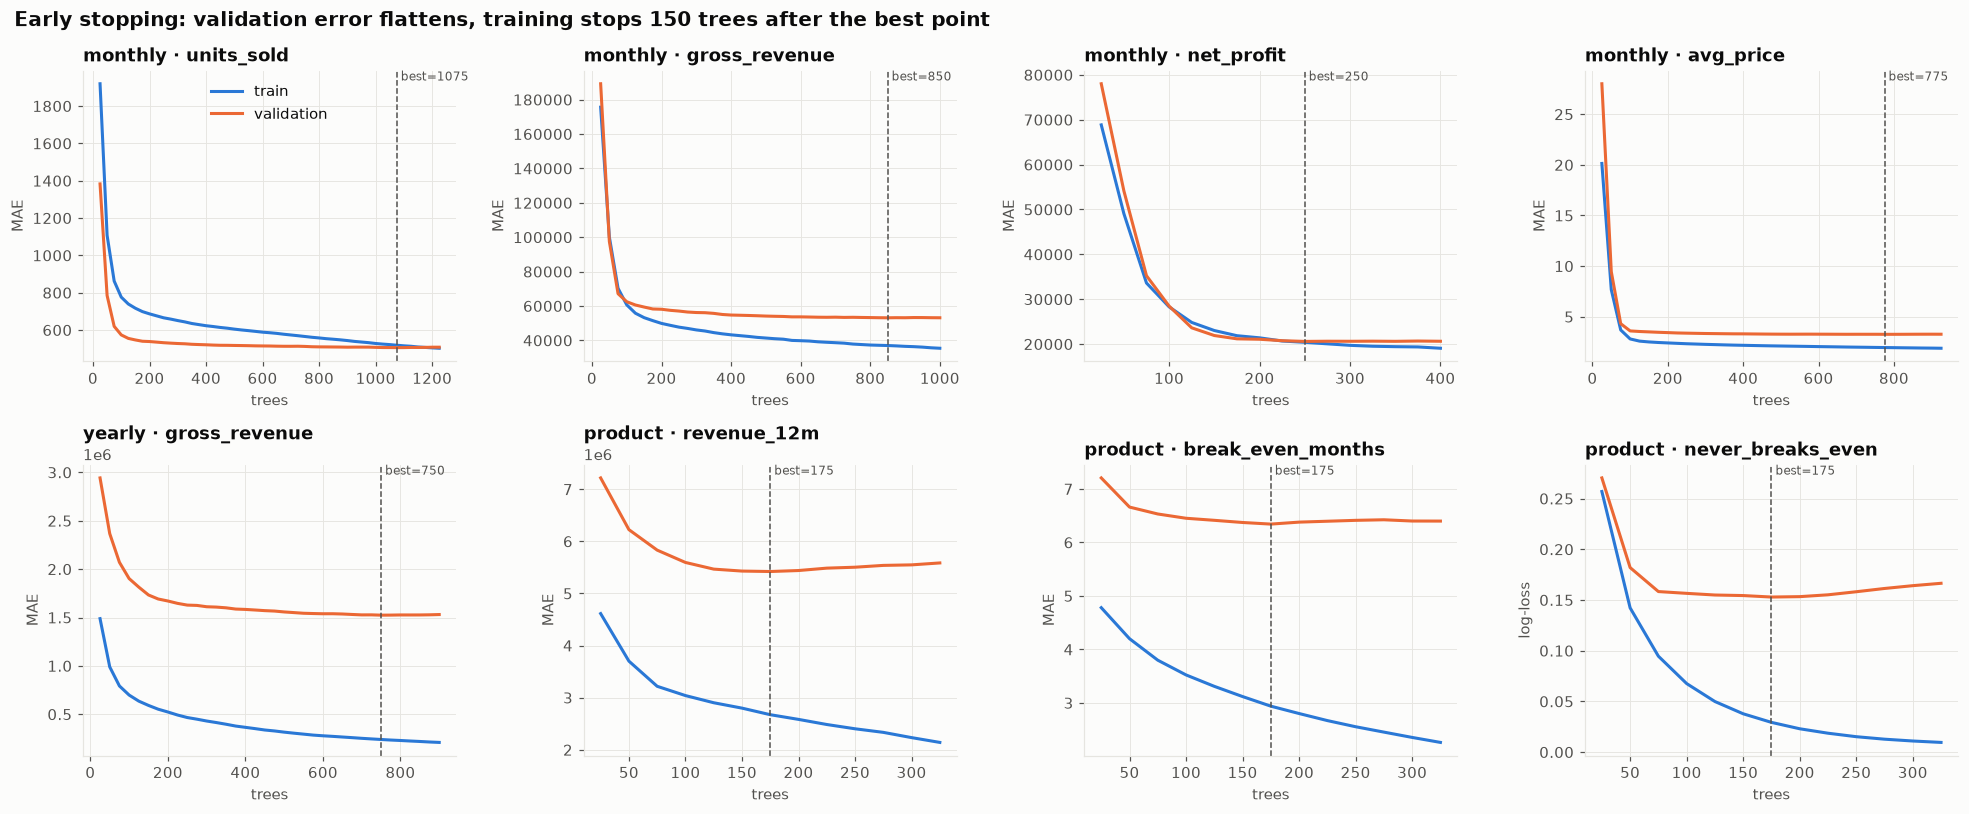

In [8]:
show_curves = [("monthly", "units_sold"), ("monthly", "gross_revenue"), ("monthly", "net_profit"), ("monthly", "avg_price"),
               ("yearly", "gross_revenue"), ("product", "revenue_12m"), ("product", "break_even_months"), ("product", "never_breaks_even")]
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, key in zip(axes.flat, show_curves):
    c = curves[key]; best = res[(res.level == key[0]) & (res.target == key[1])].best_iteration.iloc[0]
    ax.plot(c.iteration, c.train_mae, color=SERIES[0], label="train")
    ax.plot(c.iteration, c.val_mae, color=SERIES[1], label="validation")
    ax.axvline(best, color=INK2, ls="--", lw=1)
    ax.set(title=f"{key[0]} · {key[1]}", xlabel="trees", ylabel="log-loss" if key[1] == "never_breaks_even" else "MAE")
    ax.text(best, ax.get_ylim()[1], f" best={best}", va="top", color=INK2, fontsize=8)
axes[0, 0].legend()
fig.suptitle("Early stopping: validation error flattens, training stops 150 trees after the best point",
             x=.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout(); savefig(fig, "05_learning_curves")

### 5.2 Predicted vs actual (test set)

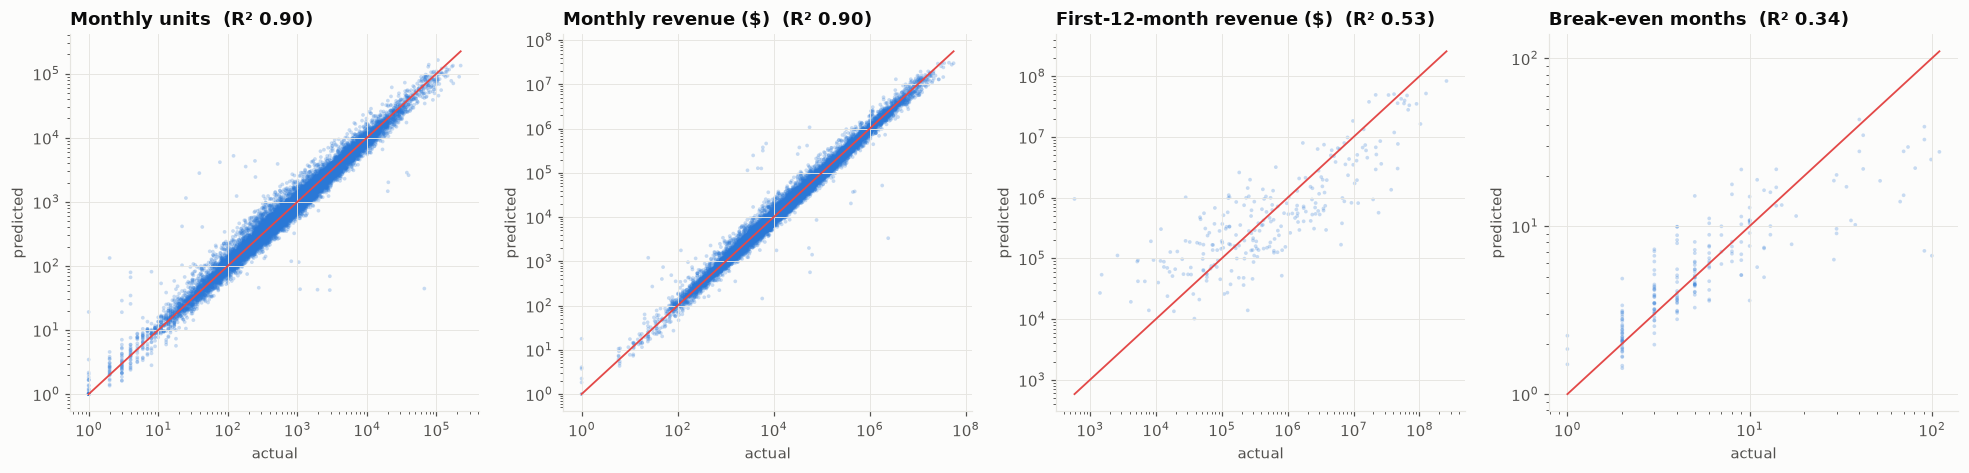

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
pairs = [(m_test, monthly_preds, "units_sold", "Monthly units", True), (m_test, monthly_preds, "gross_revenue", "Monthly revenue ($)", True),
         (p_test, product_preds, "revenue_12m", "First-12-month revenue ($)", True), (p_test, product_preds, "break_even_months", "Break-even months", True)]
for ax, (d, P, t, title, log) in zip(axes, pairs):
    y = d.loc[P[t].index, t]; p = P[t]
    ax.scatter(y.clip(lower=1), p.clip(lower=1), s=6, alpha=.25, color=SERIES[0], edgecolor="none")
    lim = [max(1, min(y.min(), p.min())), max(y.max(), p.max())]
    ax.plot(lim, lim, color=SERIES[7], lw=1.2)
    if log: ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(title=f"{title}  (R² {r2_score(y, p):.2f})", xlabel="actual", ylabel="predicted")
fig.tight_layout(); savefig(fig, "05_pred_vs_actual")

Test-year total units error: -5.42%


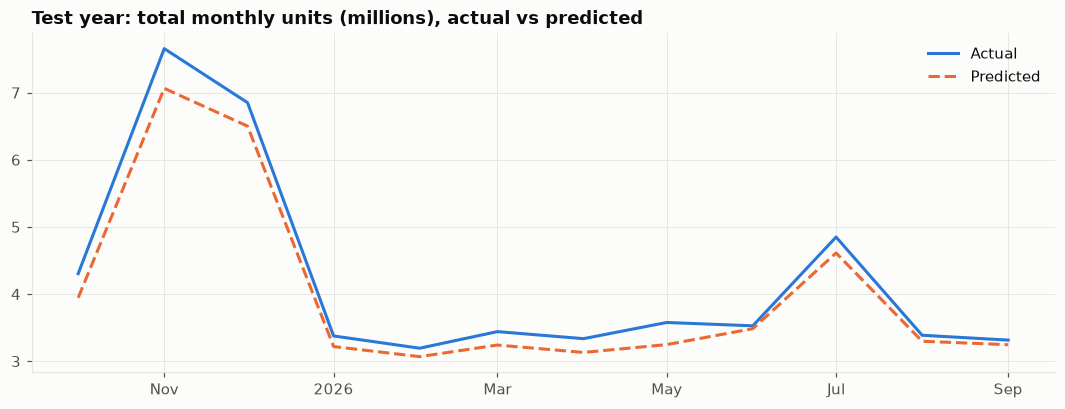

In [10]:
# Seasonality check: does the monthly model track Q4 and Prime Day peaks on the test year?
agg = m_test.assign(pred=monthly_preds["units_sold"]).groupby("month")[["units_sold", "pred"]].sum() / 1e6
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(agg.index, agg.units_sold, color=SERIES[0], label="Actual"); ax.plot(agg.index, agg.pred, color=SERIES[1], ls="--", label="Predicted")
ax.set(title="Test year: total monthly units (millions), actual vs predicted"); ax.legend(); fmt_dates(ax)
savefig(fig, "05_test_year_units")
print("Test-year total units error: %.2f%%" % ((agg.pred.sum() / agg.units_sold.sum() - 1) * 100))

### 5.3 What drives the predictions (permutation importance, top 12)

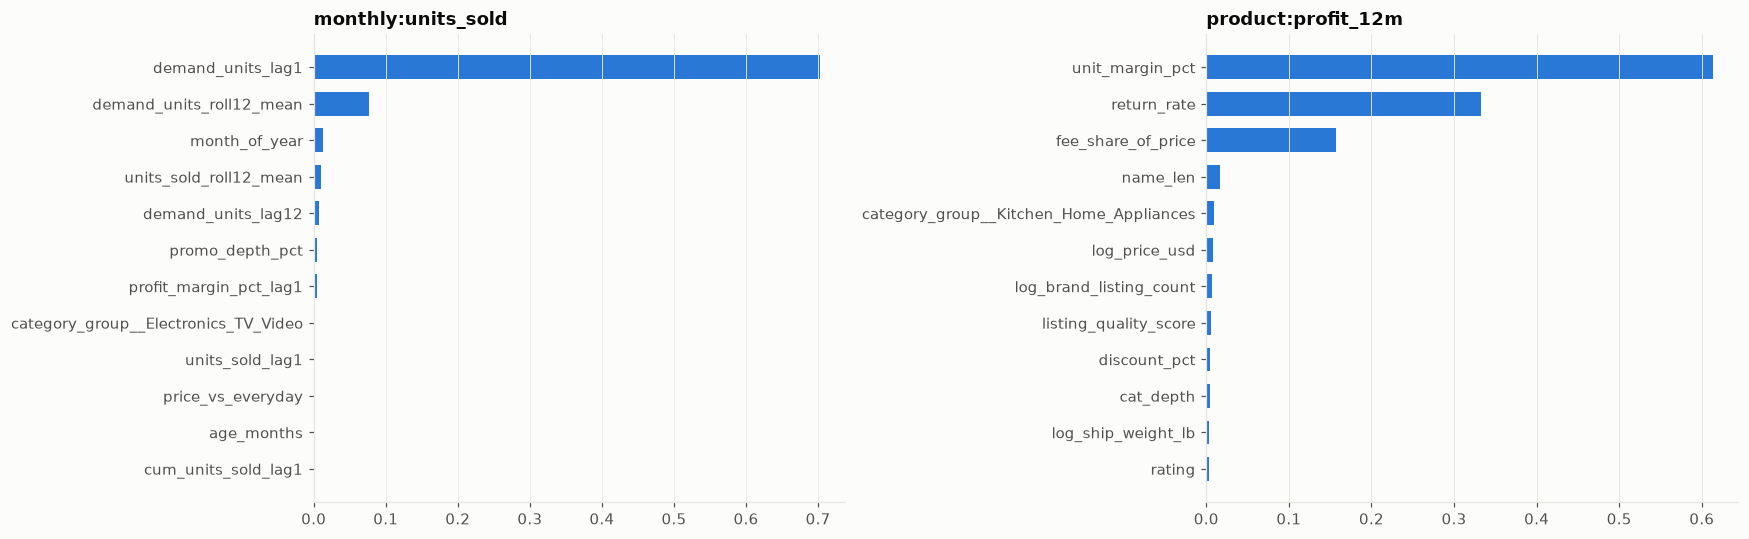

In [11]:
from sklearn.inspection import permutation_importance
imp_rows = []
for level, tgt, d in [("monthly", "units_sold", m_test.sample(4000, random_state=SEED)), ("product", "profit_12m", p_test.dropna(subset=["profit_12m"]))]:
    b = joblib.load(MODELS / level / f"{tgt}.joblib")
    fwd = TRANSFORMS[b["transform"]][0]
    r = permutation_importance(b["model"], d[b["features"]], fwd(d[tgt].values), n_repeats=3, random_state=SEED, n_jobs=-1)
    imp_rows.append(pd.Series(r.importances_mean, index=b["features"]).nlargest(12).rename(f"{level}:{tgt}"))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, s in zip(axes, imp_rows):
    ax.barh(s.index[::-1], s.values[::-1], color=SERIES[0], height=.65); ax.set(title=s.name); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "05_feature_importance")

## 6. Saved artefacts
- `models/monthly/*.joblib`, `models/yearly/*.joblib`, `models/product/*.joblib`: one file per target, each holding the fitted model,
  its feature list, the target transform (needed to invert predictions) and the best iteration.
- `reports/metrics/model_metrics.csv`: every metric in the tables above.

Load one in the backend like this:
```python
b = joblib.load("models/monthly/units_sold.joblib")
pred = TRANSFORMS[b["transform"]][1](b["model"].predict(X[b["features"]]))
```